# Customer Shopping Behavior Analysis: Retail Sales
**Author:** Vamshi Mudavath · [LinkedIn](https://www.linkedin.com/in/vamshi-mudavath-225277447) · [GitHub](https://github.com/vamshi-mudavath)

**Business question:** *How can a retail company use its customer shopping data to spot trends, improve customer engagement and sharpen its marketing and product strategy?*

Management has noticed purchasing patterns shifting across demographics, product categories and shipping options, and wants to know which factors (discounts, reviews, seasons, subscriptions, payment preferences) drive spending and repeat purchases.

**What this notebook covers**
1. Load and inspect the raw data (3,900 purchases, 18 columns)
2. Data-quality checks
3. Cleaning: missing ratings, column names, redundant columns
4. Feature engineering: age groups, purchase frequency in days, customer segments
5. Exploratory analysis with charts
6. Load the clean table into a SQL database and answer 13 business questions
7. A one-page KPI dashboard
8. Key findings and recommendations

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SQL (SQLite, PostgreSQL-compatible)

In [1]:
import sqlite3
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.spines.top": False,
                     "axes.spines.right": False, "grid.color": "#e6e6e6"})

# Paths are relative to the notebooks/ folder
RAW_CSV = Path("../data/raw/customer_shopping_behavior.csv")
PROCESSED_DIR = Path("../data/processed"); PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
DB_PATH = PROCESSED_DIR / "customer_behavior.db"
SQL_FILE = Path("../sql/business_queries.sql")
IMG_DIR = Path("../images"); IMG_DIR.mkdir(exist_ok=True)

# One colour per role, used consistently in every chart
BLUE, ORANGE, AQUA, YELLOW, GREY = "#257de0", "#f47230", "#00b894", "#f2a600", "#9aa0a6"

def save(fig, name):
    """Save a chart into ../images so the README can reuse it."""
    fig.savefig(IMG_DIR / f"{name}.png", bbox_inches="tight")

def label_bars(ax, fmt="{:,.0f}", inside=False):
    ax.set_xlim(0, max(p.get_width() for p in ax.patches) * 1.18)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k" if v >= 10000 or (v == 0 and ax.get_xlim()[1] > 10000) else f"{v:,.0f}"))
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    for p in ax.patches:
        w = p.get_width()
        ax.annotate(fmt.format(w), (w, p.get_y() + p.get_height() / 2), xytext=(4, 0),
                    textcoords="offset points", va="center", fontsize=8, color="#333")

## 1. Load and inspect the raw data

In [2]:
df = pd.read_csv(RAW_CSV)
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.head()

Rows: 3,900   Columns: 18


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   str    
 3   Item Purchased          3900 non-null   str    
 4   Category                3900 non-null   str    
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   str    
 7   Size                    3900 non-null   str    
 8   Color                   3900 non-null   str    
 9   Season                  3900 non-null   str    
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   str    
 12  Shipping Type           3900 non-null   str    
 13  Discount Applied        3900 non-null   str    
 14  Promo Code Used         3900 non-null   str    
 15

In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer ID,3900.0,NaN,NaN,NaN,1950.5,1125.977353,1.0,975.75,1950.5,2925.25,3900.0
Age,3900.0,NaN,NaN,NaN,44.068462,15.207589,18.0,31.0,44.0,57.0,70.0
Gender,3900,2,Male,2652,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Purchased,3900,25,Blouse,171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,3900,4,Clothing,1737,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purchase Amount (USD),3900.0,NaN,NaN,NaN,59.764359,23.685392,20.0,39.0,60.0,81.0,100.0
Location,3900,50,Montana,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,3900,4,M,1755,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Color,3900,25,Olive,177,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Season,3900,4,Spring,999,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data-quality checks
Before cleaning, I check for missing values, duplicates, inconsistent labels and columns that repeat the same information.

In [5]:
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("Unique customer IDs:", df["Customer ID"].nunique(), "of", len(df))

Missing values per column:
Review Rating    37
dtype: int64

Duplicate rows: 0
Unique customer IDs: 3900 of 3900


In [6]:
# Are 'Discount Applied' and 'Promo Code Used' the same information?
same = (df["Discount Applied"] == df["Promo Code Used"]).all()
print("Discount Applied == Promo Code Used on every row:", same)

# Purchase-frequency labels
print("\n", df["Frequency of Purchases"].value_counts().to_string())

Discount Applied == Promo Code Used on every row: True

 Frequency of Purchases
Every 3 Months    584
Annually          572
Quarterly         563
Monthly           553
Bi-Weekly         547
Fortnightly       542
Weekly            539


**What I found**
- `Review Rating` has **37 missing values** (about 1% of rows). Everything else is complete.
- No duplicate rows, and every row is a different customer.
- `Promo Code Used` is identical to `Discount Applied` on every row, so it adds nothing and can be dropped.
- `Bi-Weekly` and `Fortnightly` both mean *every two weeks*, and `Quarterly` and `Every 3 Months` both mean *every three months*. I keep the original labels but map both pairs to the same number of days.

One more check is worth doing: who gets discounts and subscriptions?

In [7]:
pd.crosstab(df["Gender"], [df["Discount Applied"]], normalize="index").mul(100).round(1).join(
    pd.crosstab(df["Gender"], df["Subscription Status"], normalize="index").mul(100).round(1),
    lsuffix="_discount", rsuffix="_subscribed")

,No_discount,Yes_discount,No_subscribed,Yes_subscribed
Gender,,,,
Female,100.0,0.0,100.0,0.0
Male,36.8,63.2,60.3,39.7


**Data caveat:** in this dataset **no female customer has a discount or a subscription**. That is very unlikely in a real business, so it is most likely a quirk of how the data was collected or generated. I keep the rows, but I treat any *gender × discount* or *gender × subscription* comparison with care and say so in the findings.

## 3. Cleaning

In [8]:
# 3.1 Fill missing review ratings with the median rating of the same product category
before = df["Review Rating"].isnull().sum()
df["Review Rating"] = df.groupby("Category")["Review Rating"].transform(lambda s: s.fillna(s.median()))
print(f"Missing ratings filled: {before} -> {df['Review Rating'].isnull().sum()}")

Missing ratings filled: 37 -> 0


In [9]:
# 3.2 Rename columns to snake_case so they are easy to use in Python and SQL
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
df = df.rename(columns={"purchase_amount_(usd)": "purchase_amount"})

# 3.3 Drop the redundant promo-code column
df = df.drop(columns="promo_code_used")
list(df.columns)

['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'shipping_type', 'discount_applied', 'previous_purchases', 'payment_method', 'frequency_of_purchases']

## 4. Feature engineering

In [10]:
# 4.1 Age groups: four equal-sized groups (quartiles) of customers
df["age_group"] = pd.qcut(df["age"], q=4, labels=["Young Adult", "Adult", "Middle-aged", "Senior"])

# 4.2 Purchase frequency as a number of days (same-meaning labels get the same value)
frequency_days = {"Weekly": 7, "Bi-Weekly": 14, "Fortnightly": 14, "Monthly": 30,
                  "Quarterly": 90, "Every 3 Months": 90, "Annually": 365}
df["purchase_frequency_days"] = df["frequency_of_purchases"].map(frequency_days)

# 4.3 Customer segment from purchase history
df["customer_segment"] = pd.cut(df["previous_purchases"], bins=[0, 1, 10, np.inf],
                                labels=["New", "Returning", "Loyal"])

df.groupby("age_group", observed=True)["age"].agg(["min", "max", "count"])

,min,max,count
age_group,,,
Young Adult,18,31,1028
Adult,32,44,942
Middle-aged,45,57,986
Senior,58,70,944


In [11]:
df[["age", "age_group", "frequency_of_purchases", "purchase_frequency_days",
    "previous_purchases", "customer_segment"]].head(8)

,age,age_group,frequency_of_purchases,purchase_frequency_days,previous_purchases,customer_segment
0,55,Middle-aged,Fortnightly,14,14,Loyal
1,19,Young Adult,Fortnightly,14,2,Returning
2,50,Middle-aged,Weekly,7,23,Loyal
3,21,Young Adult,Weekly,7,49,Loyal
4,45,Middle-aged,Annually,365,31,Loyal
5,46,Middle-aged,Weekly,7,14,Loyal
6,63,Senior,Quarterly,90,49,Loyal
7,27,Young Adult,Weekly,7,19,Loyal


In [12]:
# Save the analysis-ready table
df.to_csv(PROCESSED_DIR / "customer_shopping_clean.csv", index=False)
print("Saved:", PROCESSED_DIR / "customer_shopping_clean.csv", df.shape)

Saved: ../data/processed/customer_shopping_clean.csv (3900, 20)


## 5. Exploratory analysis

In [13]:
kpis = {
    "Customers / orders": f"{len(df):,}",
    "Total revenue (USD)": f"{df['purchase_amount'].sum():,}",
    "Average order value (USD)": f"{df['purchase_amount'].mean():.2f}",
    "Average review rating": f"{df['review_rating'].mean():.2f} / 5",
    "Subscribers": f"{(df['subscription_status'] == 'Yes').mean():.1%}",
    "Orders with a discount": f"{(df['discount_applied'] == 'Yes').mean():.1%}",
    "Average previous purchases": f"{df['previous_purchases'].mean():.1f}",
}
pd.Series(kpis, name="value").to_frame()

,value
Customers / orders,"3,900"
Total revenue (USD),"233,081"
Average order value (USD),59.76
Average review rating,3.75 / 5
Subscribers,27.0%
Orders with a discount,43.0%
Average previous purchases,25.4


### 5.1 Where does the revenue come from?

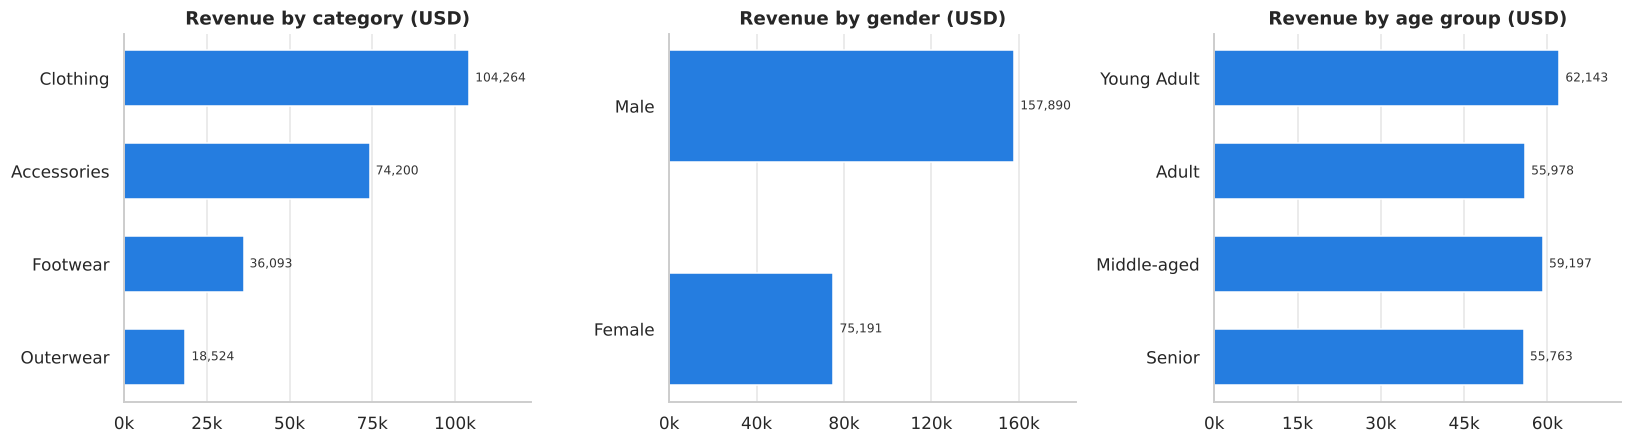

category
Clothing       44.7
Accessories    31.8
Footwear       15.5
Outerwear       7.9


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

cat = df.groupby("category")["purchase_amount"].sum().sort_values()
axes[0].barh(cat.index, cat.values, color=BLUE, height=0.6)
axes[0].set_title("Revenue by category (USD)"); label_bars(axes[0])

gen = df.groupby("gender")["purchase_amount"].sum().sort_values()
axes[1].barh(gen.index, gen.values, color=BLUE, height=0.5)
axes[1].set_title("Revenue by gender (USD)"); label_bars(axes[1])

age = df.groupby("age_group", observed=True)["purchase_amount"].sum()
axes[2].barh(age.index.astype(str), age.values, color=BLUE, height=0.6)
axes[2].invert_yaxis(); axes[2].set_title("Revenue by age group (USD)"); label_bars(axes[2])

for ax in axes: ax.set_xlabel(""); ax.grid(axis="y", visible=False)
plt.tight_layout(); save(fig, "revenue_breakdown"); plt.show()

print((cat / cat.sum() * 100).round(1).sort_values(ascending=False).to_string())

- **Clothing (44.7%) and Accessories (31.8%) bring in about three quarters of revenue.** Outerwear is the smallest category.
- **Male customers bring in 67.7% of revenue**, mainly because there are twice as many of them (2,652 vs 1,248). Spend *per order* is almost the same (USD 59.54 vs 60.25).
- **Young adults (18–31) are the top age group** at USD 62,143, but the four groups are close (USD 55.8k–62.1k).

### 5.2 Do subscriptions, discounts and shipping change how much people spend?

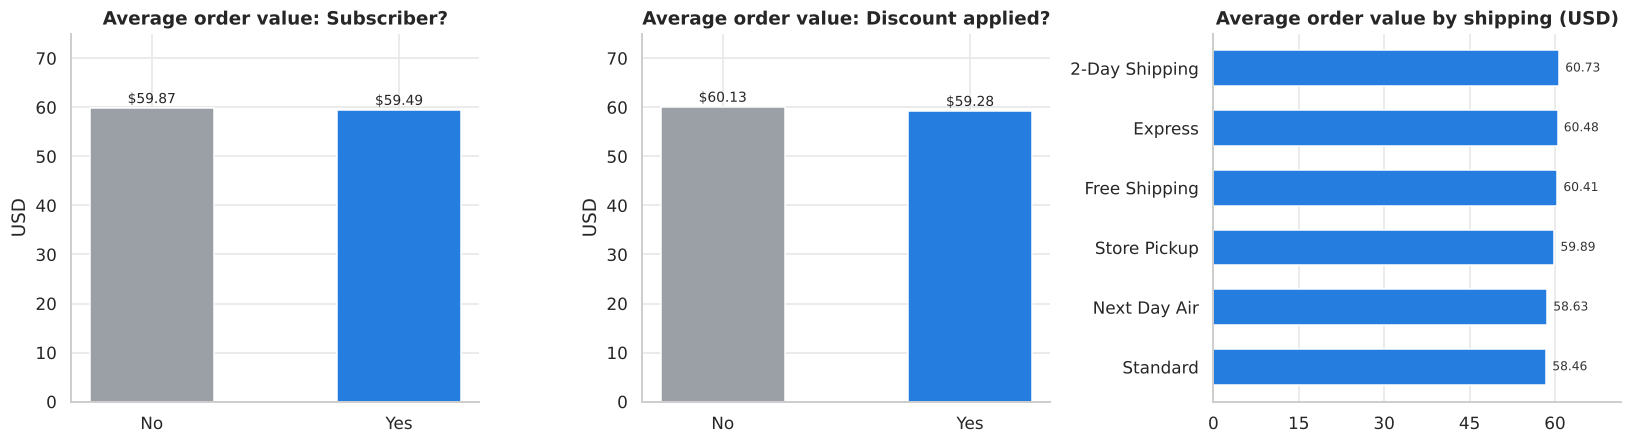

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for ax, col, title in [(axes[0], "subscription_status", "Subscriber?"),
                       (axes[1], "discount_applied", "Discount applied?")]:
    m = df.groupby(col)["purchase_amount"].mean()
    ax.bar(m.index, m.values, color=[GREY, BLUE], width=0.5)
    for i, v in enumerate(m.values): ax.text(i, v + 1, f"${v:.2f}", ha="center", fontsize=9)
    ax.set_ylim(0, 75); ax.set_title(f"Average order value: {title}"); ax.set_ylabel("USD")

ship = df.groupby("shipping_type")["purchase_amount"].mean().sort_values()
axes[2].barh(ship.index, ship.values, color=BLUE, height=0.6)
axes[2].set_title("Average order value by shipping (USD)")
label_bars(axes[2], "{:.2f}")
axes[2].grid(axis="y", visible=False)
plt.tight_layout(); save(fig, "spend_drivers"); plt.show()

- **Subscribers do not spend more per order** (USD 59.49 vs 59.87 for non-subscribers). The subscription is not lifting basket size.
- **Discounted orders are only slightly smaller** (USD 59.28 vs 60.13), so discounts are not obviously cheapening the basket, but they are not growing it either.
- **Shipping type barely matters**: averages range from USD 58.46 (Standard) to 60.73 (2-Day). Express customers spend about USD 2 more per order than Standard ones.

### 5.3 Products: what sells, what is rated well, what needs a discount?

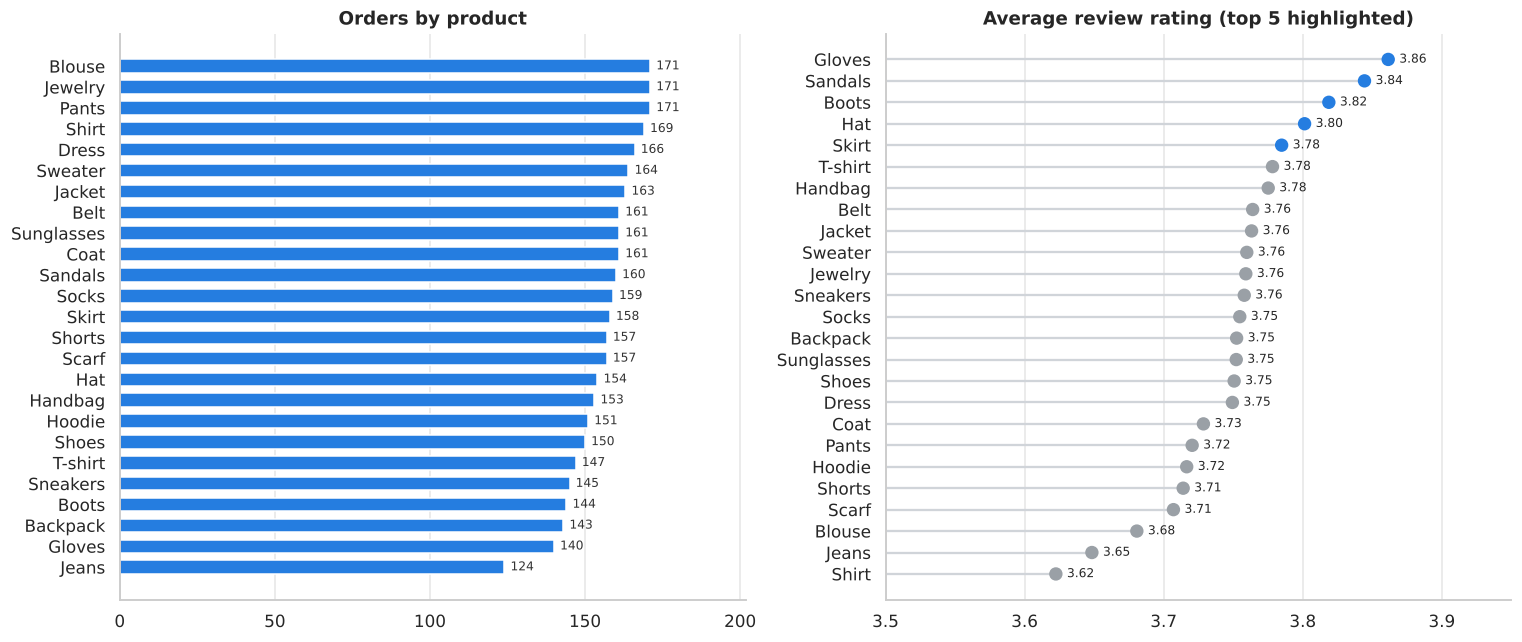

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

items = df["item_purchased"].value_counts().sort_values()
axes[0].barh(items.index, items.values, color=BLUE, height=0.65)
axes[0].set_title("Orders by product"); label_bars(axes[0])

rating = df.groupby("item_purchased")["review_rating"].mean().sort_values()
colors = [BLUE if r >= rating.nlargest(5).min() else GREY for r in rating.values]
axes[1].hlines(rating.index, 3.5, rating.values, color="#d0d4d9", linewidth=1.5)
axes[1].scatter(rating.values, rating.index, color=colors, s=60, zorder=3)
for y, v in enumerate(rating.values): axes[1].text(v + 0.008, y, f"{v:.2f}", va="center", fontsize=8)
axes[1].set_xlim(3.5, 3.95); axes[1].set_title("Average review rating (top 5 highlighted)")
for ax in axes: ax.grid(axis="y", visible=False)
plt.tight_layout(); save(fig, "products"); plt.show()

- **Blouse, Jewelry, Pants, Shirt and Dress** are the most ordered items.
- **Gloves (3.86), Sandals (3.84), Boots (3.82), Hat (3.80) and Skirt (3.78)** have the best ratings, but every product sits between about 3.6 and 3.9, so no product is clearly loved or clearly failing.

### 5.4 Seasons, payment methods and customer segments

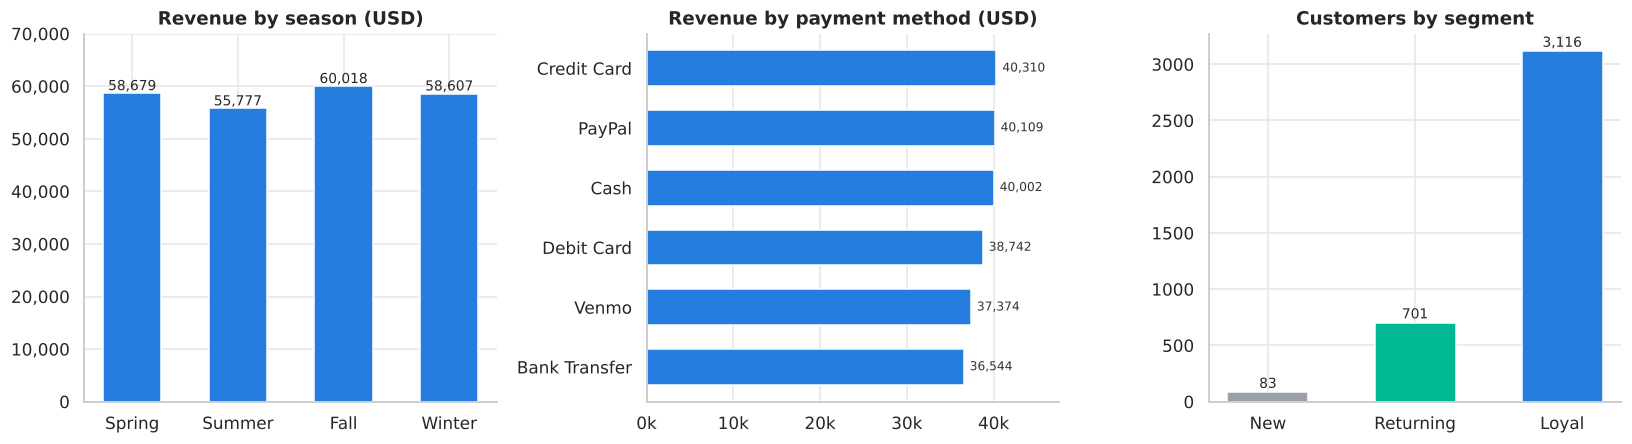

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

season = df.groupby("season")["purchase_amount"].sum().reindex(["Spring", "Summer", "Fall", "Winter"])
axes[0].bar(season.index, season.values, color=BLUE, width=0.55)
for i, v in enumerate(season.values): axes[0].text(i, v + 600, f"{v:,}", ha="center", fontsize=9)
axes[0].set_ylim(0, 70000); axes[0].set_title("Revenue by season (USD)")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))

pay = df.groupby("payment_method")["purchase_amount"].sum().sort_values()
axes[1].barh(pay.index, pay.values, color=BLUE, height=0.6)
axes[1].set_title("Revenue by payment method (USD)"); label_bars(axes[1])
axes[1].grid(axis="y", visible=False)

seg = df["customer_segment"].value_counts().reindex(["New", "Returning", "Loyal"])
axes[2].bar(seg.index.astype(str), seg.values, color=[GREY, AQUA, BLUE], width=0.55)
for i, v in enumerate(seg.values): axes[2].text(i, v + 40, f"{v:,}", ha="center", fontsize=9)
axes[2].set_title("Customers by segment")
plt.tight_layout(); save(fig, "season_payment_segments"); plt.show()

- **Fall is the strongest season** (USD 60,018, with the highest average order of USD 61.56); Summer is the weakest (USD 55,777).
- **Payment methods are evenly split**: Credit Card, PayPal and Cash lead, each around USD 40k.
- **80% of customers are already "Loyal"** (more than 10 previous purchases). Only 83 customers are new, so the business depends heavily on its existing base.

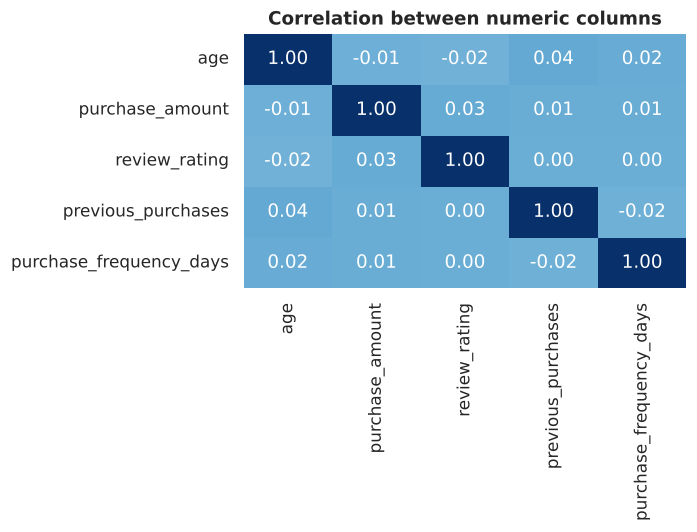

In [18]:
num = df[["age", "purchase_amount", "review_rating", "previous_purchases", "purchase_frequency_days"]]
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1, cbar=False, ax=ax)
ax.set_title("Correlation between numeric columns")
plt.tight_layout(); save(fig, "correlation_heatmap"); plt.show()

None of the numeric columns are related to each other (all correlations are close to 0). Age, rating and purchase history do **not** predict how much a customer spends on one order, so revenue growth has to come from **more orders and more customers**, not bigger baskets.

## 6. Business questions in SQL
The clean table is loaded into a SQL database as `customer`. I use **SQLite** so the notebook runs anywhere with no setup; the queries in `sql/business_queries.sql` are written to also run on **PostgreSQL** (see the optional cell at the end).

In [19]:
conn = sqlite3.connect(DB_PATH)
df.assign(age_group=df["age_group"].astype(str),
          customer_segment=df["customer_segment"].astype(str)).to_sql("customer", conn, if_exists="replace", index=False)
print(pd.read_sql("SELECT COUNT(*) AS rows_loaded FROM customer", conn))

   rows_loaded
0         3900


In [20]:
# Split the .sql file into its numbered questions so each one can be run and shown separately
queries, title, body = {}, None, []
for line in SQL_FILE.read_text(encoding="utf-8").splitlines():
    if line.startswith("-- Q"):
        if title: queries[title] = "\n".join(body)
        title, body = line[3:].strip(), []
    elif title and not line.startswith("-- ="):
        body.append(line)
queries[title] = "\n".join(body)

def run(n):
    key = next(k for k in queries if k.startswith(f"Q{n}."))
    print(key)
    return pd.read_sql(queries[key], conn)

print(len(queries), "queries loaded")

13 queries loaded


In [21]:
run(1)

Q1. Revenue by gender: how much do male and female customers spend in total?


,gender,orders,revenue,revenue_share_pct
0,Male,2652,157890,67.7
1,Female,1248,75191,32.3


In [22]:
run(2)

Q2. Discount users who still spent more than the average purchase amount


,customers,their_avg_spend,overall_avg_spend
0,839,79.79,59.76


In [23]:
run(3)

Q3. Top 5 products by average review rating


,item_purchased,orders,avg_rating
0,Gloves,140,3.86
1,Sandals,160,3.84
2,Boots,144,3.82
3,Hat,154,3.80
4,Skirt,158,3.78


In [24]:
run(4)

Q4. Average purchase amount by shipping type (Standard vs Express and the rest)


,shipping_type,orders,avg_purchase
0,2-Day Shipping,627,60.73
1,Express,646,60.48
2,Free Shipping,675,60.41
3,Store Pickup,650,59.89
4,Next Day Air,648,58.63
5,Standard,654,58.46


In [25]:
run(5)

Q5. Do subscribers spend more? Average spend and total revenue by subscription status


,subscription_status,customers,avg_spend,total_revenue
0,No,2847,59.87,170436
1,Yes,1053,59.49,62645


In [26]:
run(6)

Q6. Top 5 products most often bought with a discount


,item_purchased,orders,discount_rate_pct
0,Hat,154,50.00
1,Sneakers,145,49.66
2,Coat,161,49.07
3,Sweater,164,48.17
4,Pants,171,47.37


In [27]:
run(7)

Q7. Customer segments (New = 1 previous purchase, Returning = 2-10, Loyal = more than 10)


,customer_segment,customers,avg_spend
0,Loyal,3116,59.54
1,Returning,701,60.93
2,New,83,58.47


In [28]:
run(8)

Q8. Top 3 most purchased products in each category (window function)


,category,item_rank,item_purchased,orders
0,Accessories,1,Jewelry,171
1,Accessories,2,Belt,161
2,Accessories,3,Sunglasses,161
3,Clothing,1,Blouse,171
4,Clothing,2,Pants,171
5,Clothing,3,Shirt,169
6,Footwear,1,Sandals,160
7,Footwear,2,Shoes,150
8,Footwear,3,Sneakers,145
9,Outerwear,1,Jacket,163


In [29]:
run(9)

Q9. Are repeat buyers (more than 5 previous purchases) more likely to subscribe?


,buyer_type,customers,subscribed_pct
0,Occasional (<=5),424,22.4
1,Repeat buyer (>5),3476,27.6


In [30]:
run(10)

Q10. Revenue contribution of each age group


,age_group,min_age,max_age,revenue,revenue_share_pct
0,Young Adult,18,31,62143,26.7
1,Middle-aged,45,57,59197,25.4
2,Adult,32,44,55978,24.0
3,Senior,58,70,55763,23.9


In [31]:
run(11)

Q11. Revenue and average order value by season


,season,orders,revenue,avg_purchase
0,Fall,975,60018,61.56
1,Spring,999,58679,58.74
2,Winter,971,58607,60.36
3,Summer,955,55777,58.41


In [32]:
run(12)

Q12. Data check: who receives discounts and subscriptions, split by gender?


,gender,discount_pct,subscribed_pct
0,Female,0.0,0.0
1,Male,63.2,39.7


In [33]:
run(13)

Q13. Top 5 states by revenue


,location,orders,revenue
0,Montana,96,5784
1,Illinois,92,5617
2,California,95,5605
3,Idaho,93,5587
4,Nevada,87,5514


**What SQL adds**
- **Q2:** 839 customers used a discount *and* still spent at or above the average (USD 59.76). Their average order is USD 79.79.
- **Q6:** Hat (50.0%), Sneakers (49.7%), Coat (49.1%), Sweater (48.2%) and Pants (47.4%) are the items most often sold at a discount. These are the first places to test smaller discounts.
- **Q9:** Repeat buyers subscribe more often than occasional buyers (27.6% vs 22.4%), but 72% of repeat buyers still have no subscription, so there is a large pool to convert.
- **Q12** confirms the data caveat: discounts and subscriptions appear only for male customers.

## 7. One-page KPI dashboard

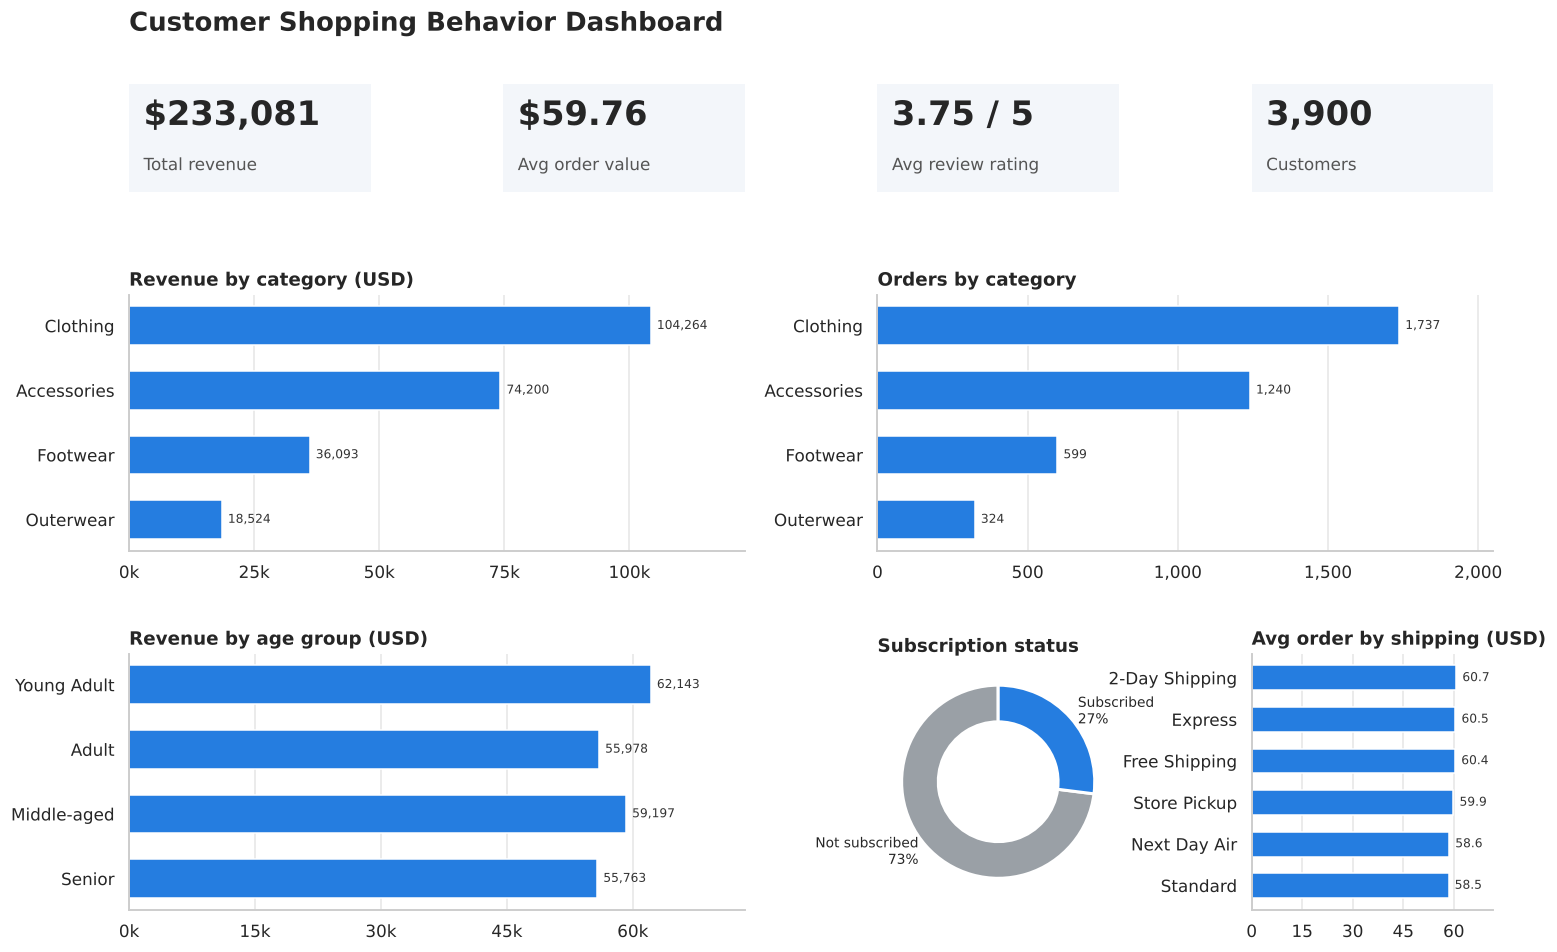

In [34]:
fig = plt.figure(figsize=(16, 9.5))
gs = fig.add_gridspec(3, 4, height_ratios=[0.42, 1, 1], hspace=0.5, wspace=0.55, top=0.9)
fig.suptitle("Customer Shopping Behavior Dashboard", fontsize=17, fontweight="bold", x=0.125, ha="left", y=0.97)

cards = [("Total revenue", f"${df['purchase_amount'].sum():,}"),
         ("Avg order value", f"${df['purchase_amount'].mean():.2f}"),
         ("Avg review rating", f"{df['review_rating'].mean():.2f} / 5"),
         ("Customers", f"{len(df):,}")]
for i, (t, v) in enumerate(cards):
    ax = fig.add_subplot(gs[0, i]); ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color="#f3f6fa", zorder=0))
    ax.text(0.06, 0.62, v, fontsize=22, fontweight="bold", transform=ax.transAxes)
    ax.text(0.06, 0.2, t, fontsize=11, color="#555", transform=ax.transAxes)

def hbar(ax, s, title, fmt="{:,.0f}"):
    ax.barh(s.index.astype(str), s.values, color=BLUE, height=0.6); ax.set_title(title, loc="left")
    label_bars(ax, fmt); ax.grid(axis="y", visible=False); ax.set_xlabel("")

hbar(fig.add_subplot(gs[1, 0:2]), df.groupby("category")["purchase_amount"].sum().sort_values(), "Revenue by category (USD)")
hbar(fig.add_subplot(gs[1, 2:4]), df["category"].value_counts().sort_values(), "Orders by category")
ax = fig.add_subplot(gs[2, 0:2])
hbar(ax, df.groupby("age_group", observed=True)["purchase_amount"].sum(), "Revenue by age group (USD)"); ax.invert_yaxis()

ax = fig.add_subplot(gs[2, 2])
sub = df["subscription_status"].value_counts()
ax.pie(sub.values, labels=[f"{'Subscribed' if k == 'Yes' else 'Not subscribed'}\n{v / len(df):.0%}" for k, v in sub.items()],
       colors=[GREY, BLUE], startangle=90, wedgeprops=dict(width=0.38, edgecolor="white", linewidth=2), textprops={"fontsize": 9})
ax.set_title("Subscription status", loc="left")

ax = fig.add_subplot(gs[2, 3])
hbar(ax, df.groupby("shipping_type")["purchase_amount"].mean().sort_values(), "Avg order by shipping (USD)", "{:.1f}")
save(fig, "kpi_dashboard"); plt.show()

An interactive version of this dashboard (with filters for gender, category, season, subscription, age group and shipping type) is in `docs/index.html` and is published on GitHub Pages.

## 8. Key findings
1. **Revenue is concentrated in two categories.** Clothing and Accessories bring in 76.5% of the USD 233,081 total.
2. **Order size is flat everywhere.** Average order value stays around USD 58–62 across gender, age, season, shipping, subscription and discount. No numeric feature correlates with spend.
3. **Subscriptions are not paying off.** 27% of customers subscribe, but subscribers spend slightly *less* per order (USD 59.49 vs 59.87). Repeat buyers subscribe a little more often (27.6% vs 22.4%), yet 72% of them still have not subscribed.
4. **Discounts are used heavily** (43% of orders), without a clear gain in basket size. Hats, Sneakers and Coats are discounted almost half the time.
5. **The customer base is mature.** 80% of customers have more than 10 previous purchases; only 2% are new.
6. **Fall is the best season** for both revenue and average order value; Summer is the weakest.
7. **Data caveat:** discounts and subscriptions are recorded only for male customers, so gender comparisons on those two factors are not reliable.

## 9. Recommendations
- **Rework the subscription offer.** It is not lifting spend today. Test member-only perks tied to bigger baskets (free express shipping above a threshold, early access to new collections).
- **Tighten discounts on the most-discounted items** (Hats, Sneakers, Coats, Sweaters, Pants) and measure whether sales hold.
- **Invest in acquisition.** With only 2% new customers, growth must come from new buyers; Young Adults are the largest age group to target.
- **Plan inventory and campaigns around Fall**, and use Summer promotions to lift the weakest season.
- **Promote top-rated products** (Gloves, Sandals, Boots) in campaigns, and look into why ratings are average across the range.
- **Fix data collection** so discounts and subscriptions are tracked for all customers, then repeat the gender analysis.

## Optional: load into PostgreSQL instead of SQLite
The SQL file also runs on PostgreSQL. To use it, create a database called `customer_behavior` in pgAdmin, install the drivers (`pip install sqlalchemy psycopg2-binary`), then run:

```python
from sqlalchemy import create_engine
engine = create_engine("postgresql+psycopg2://postgres:<your_password>@localhost:5432/customer_behavior")
df.to_sql("customer", engine, if_exists="replace", index=False)
pd.read_sql("SELECT * FROM customer LIMIT 5", engine)
```

Never commit a real password to GitHub; keep it in an environment variable instead.

In [35]:
conn.close()
print("Analysis complete. Charts saved to ../images, clean data and SQLite DB saved to ../data/processed")

Analysis complete. Charts saved to ../images, clean data and SQLite DB saved to ../data/processed
